In [9]:
import geopandas as gpd
import networkx as nx
import pandas as pd
import pickle
# Paths to your shapefiles
road_links_path = 'road_ExportFeatures.shp'
rail_links_path = 'rail_ExportFeatures.shp'
facility_nodes_path = 'intermodal_ExportFeatures.shp'

# Load the shapefiles
road_links_gdf = gpd.read_file(road_links_path)
rail_links_gdf = gpd.read_file(rail_links_path)
facility_nodes_gdf = gpd.read_file(facility_nodes_path)

# Combine road and rail links into a single GeoDataFrame using pd.concat
links_gdf = pd.concat([road_links_gdf, rail_links_gdf], ignore_index=True)

# Create a NetworkX graph
G = nx.Graph()

# Function to add edges from links GeoDataFrame
def add_edges_from_gdf(gdf, graph):
    for idx, row in gdf.iterrows():
        start_node = row.geometry.coords[0]  # Get the start coordinates from geometry
        end_node = row.geometry.coords[-1]  # Get the end coordinates from geometry
        graph.add_edge(start_node, end_node, weight=row['Length'])  # Using 'Length' as the weight

# Add edges to the graph
add_edges_from_gdf(links_gdf, G)

# Function to add facility nodes from nodes GeoDataFrame
def add_nodes_from_gdf(gdf, graph):
    for idx, row in gdf.iterrows():
        node = row.geometry.coords[0]  # Get the coordinates from geometry
        graph.add_node(node, **row.to_dict())

# Add facility nodes to the graph
add_nodes_from_gdf(facility_nodes_gdf, G)

# Save the NetworkX graph using pickle
with open('path_to_save_graph.pkl', 'wb') as f:
    pickle.dump(G, f)

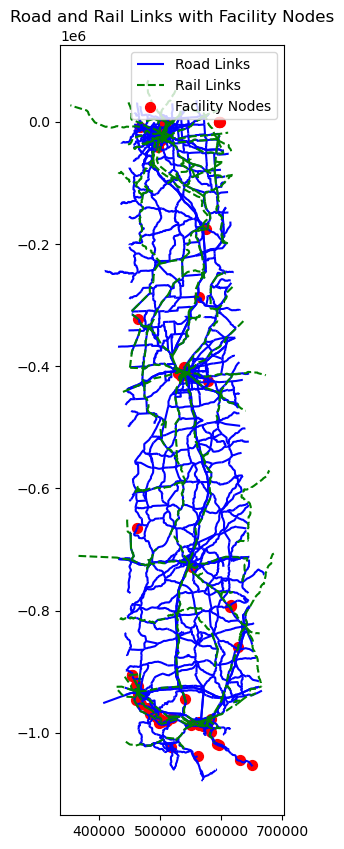

In [19]:
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx

# Paths to your shapefiles
road_links_path = 'road_ExportFeatures.shp'
rail_links_path = 'rail_ExportFeatures.shp'
facility_nodes_path = 'intermodal_ExportFeatures.shp'

# Load road, rail links, and facility nodes as GeoDataFrames
road_links_gdf = gpd.read_file(road_links_path)
rail_links_gdf = gpd.read_file(rail_links_path)
facility_nodes_gdf = gpd.read_file(facility_nodes_path)

# Initialize figure and axes
plt.figure(figsize=(12, 10))
ax = plt.subplot(111)

# Plot road links
road_links_gdf.plot(ax=ax, color='blue', linewidth=1.5, label='Road Links')

# Plot rail links
rail_links_gdf.plot(ax=ax, color='green', linestyle='dashed', linewidth=1.5, label='Rail Links')

# Plot facility nodes
facility_nodes_gdf.plot(ax=ax, color='red', markersize=50, label='Facility Nodes', marker='o')

# Add legend and title
plt.legend()
plt.title('Road and Rail Links with Facility Nodes')

# Show plot
plt.show()

In [20]:
import gurobipy as gp
from gurobipy import GRB
import networkx as nx
import matplotlib.pyplot as plt
import geopandas as gpd
import random

# Load shapefiles for road links, rail links, and facility nodes
road_links_path = 'road_ExportFeatures.shp'
rail_links_path = 'rail_ExportFeatures.shp'
facility_nodes_path = 'intermodal_ExportFeatures.shp'

# Load road, rail links, and facility nodes as GeoDataFrames
road_links_gdf = gpd.read_file(road_links_path)
rail_links_gdf = gpd.read_file(rail_links_path)
facility_nodes_gdf = gpd.read_file(facility_nodes_path)

# Initialize the graph
G = nx.DiGraph()

# Add road links to the graph
for idx, row in road_links_gdf.iterrows():
    G.add_edge(row['start_node'], row['end_node'], mode='road', distance=row['distance'], cost=row['distance'] * rc)

# Add rail links to the graph
for idx, row in rail_links_gdf.iterrows():
    G.add_edge(row['start_node'], row['end_node'], mode='rail', distance=row['distance'], cost=row['distance'] * tc)

# Add facility nodes to the graph
for idx, row in facility_nodes_gdf.iterrows():
    G.add_node(row['node_id'])

# Define nodes and OD pairs dynamically from facility_nodes_gdf
nodes = list(G.nodes())
origins = facility_nodes_gdf[facility_nodes_gdf['node_type'] == 'origin']['node_id'].tolist()
destinations = facility_nodes_gdf[facility_nodes_gdf['node_type'] == 'destination']['node_id'].tolist()
intermediate_nodes = facility_nodes_gdf[facility_nodes_gdf['node_type'] == 'intermodal_facility']['node_id'].tolist()

# Example OD pairs with flow (using random flow for illustration)
od_pairs = [(o, d, random.randint(1000, 5000)) for o in origins for d in destinations]

# Cost dictionary including distances and cost multipliers
costs = {(u, v, mode): G[u][v]['cost'] for u, v, mode in G.edges(data='mode')}
fixed_costs = {hub: random.randint(200000, 400000) for hub in intermediate_nodes}
discount_rate = 1.005
M = 1000000

# Create model
m = gp.Model('IntermodalHubLocation')

# Variables
arcs = [(u, v, d['mode']) for u, v, d in G.edges(data=True)]
x = m.addVars(arcs, od_pairs, vtype=GRB.CONTINUOUS, name="x")
z = m.addVars(intermediate_nodes, vtype=GRB.BINARY, name="z")

# Objective function
m.setObjective(
    gp.quicksum(costs[i, j, mode] * x[i, j, mode, o, d] for (i, j, mode) in arcs for (o, d, f) in od_pairs) +
    discount_rate * gp.quicksum(fixed_costs[i] * z[i] for i in intermediate_nodes),
    GRB.MINIMIZE
)

# Flow conservation constraints
for i in nodes:
    for o, d, f in od_pairs:
        inflow = gp.quicksum(x[j, i, mode, o, d] for j in nodes for mode in ['road', 'rail'] if (j, i, mode) in arcs and j != i)
        outflow = gp.quicksum(x[i, j, mode, o, d] for j in nodes for mode in ['road', 'rail'] if (i, j, mode) in arcs and i != j)
        if i == o:
            m.addConstr(outflow - inflow == f, name=f"flow_conservation_{i}_{o}_{d}")
        elif i == d:
            m.addConstr(outflow - inflow == -f, name=f"flow_conservation_{i}_{o}_{d}")
        else:
            m.addConstr(outflow - inflow == 0, name=f"flow_conservation_{i}_{o}_{d}")

# Hub capacity constraints
for i in intermediate_nodes:
    for o, d, f in od_pairs:
        m.addConstr(
            gp.quicksum(x[i, j, mode, o, d] for j in nodes for mode in ['road', 'rail'] if (i, j, mode) in arcs and i != j) <= M * z[i],
            name=f"hub_capacity_{i}_{o}_{d}"
        )

# Non-negativity constraints
m.addConstrs((x[i, j, mode, o, d] >= 0 for (i, j, mode) in arcs for (o, d, f) in od_pairs), name="non_negativity")

# Optimize the model
m.optimize()

# Check feasibility and print results
if m.status == GRB.INFEASIBLE:
    print("Model is infeasible. Computing Irreducible Inconsistent Subsystem (IIS)...")
    m.computeIIS()
    print("\nThe following constraints are infeasible:")
    for c in m.getConstrs():
        if c.IISConstr:
            print(f"- {c.ConstrName}")
else:
    print('Optimal objective:', m.objVal)
    for v in m.getVars():
        if v.x > 0:
            print(f'{v.varName}: {v.x}')

# Print hub selections
for i in intermediate_nodes:
    print(f'Hub {i} selected: {z[i].x}')


KeyError: 'start_node'

In [21]:
import geopandas as gpd

# Paths to your shapefiles
road_links_path = 'road_ExportFeatures.shp'
rail_links_path = 'rail_ExportFeatures.shp'
facility_nodes_path = 'intermodal_ExportFeatures.shp'

# Load the shapefiles
road_links_gdf = gpd.read_file(road_links_path)
rail_links_gdf = gpd.read_file(rail_links_path)
facility_nodes_gdf = gpd.read_file(facility_nodes_path)

# Print column names to verify
print("Road Links Columns: ", road_links_gdf.columns)
print("Rail Links Columns: ", rail_links_gdf.columns)
print("Facility Nodes Columns: ", facility_nodes_gdf.columns)


Road Links Columns:  Index(['STATE', 'Free_Speed', 'Name', 'Link_Type', 'Dir_Flag', 'Urban_Rura',
       'Limited_Ac', 'Volume', 'Capacity', 'VCR', 'Artificial', 'Mode_Type',
       'Length', 'Shape_Leng', 'geometry'],
      dtype='object')
Rail Links Columns:  Index(['State', 'Name', 'Link_Type', 'Dir_Flag', 'Volume', 'Capacity', 'VCR',
       'Artificial', 'Mode_Type', 'Length', 'Shape_Leng', 'geometry'],
      dtype='object')
Facility Nodes Columns:  Index(['Facility_I', 'Name', 'Address', 'City', 'State', 'Source', 'Rail',
       'Operator', 'Website', 'Other_Link', 'Google_Map', 'Notes', 'IM_Source',
       'ID', 'Zip_Code', 'Road', 'Pipeline', 'Water', 'Volume', 'Capacity',
       'VCR', 'geometry'],
      dtype='object')


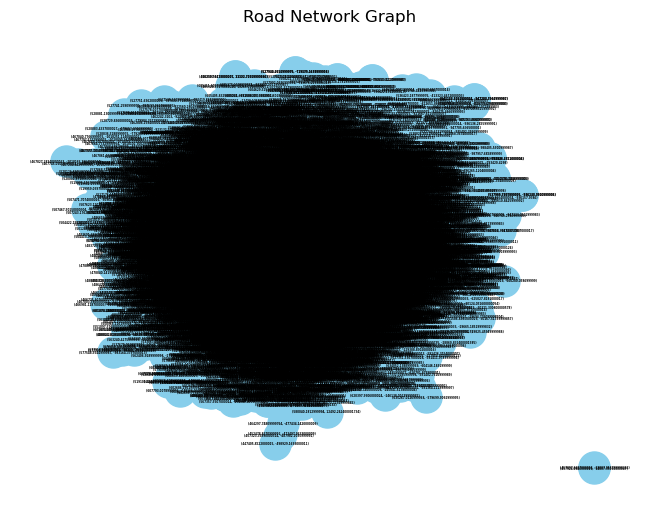

In [25]:
import geopandas as gpd
import networkx as nx

road_links_gdf = gpd.read_file('road_ExportFeatures.shp')
from shapely.geometry import LineString

# Buffer and dissolve to combine nearby road segments
dissolved = road_links_gdf.geometry.buffer(0.01).unary_union

# Convert back to GeoDataFrame with LineString geometry
aggregated_gdf = gpd.GeoDataFrame(geometry=[geom for geom in dissolved], crs=road_links_gdf.crs)
